# Practical task: Modelling hotel cancellations

# Task

The aim of this task is to create a model or set of models which could be used to predict whether a customer is going to cancel a hotel booking.

To pass, you should include, at least:
* Some exploratory data analysis to justify features used in the model
* At least two different binary classification models
* Markdown boxes to compare the models and to explain your process and observations

For a full explanation of the marking criteria, see the documents in Integral.

<a id='intro'></a>
# Introduction

This data set contains information on 119,390 hotel bookings between July 2015 and August 2017. Each observation represents a hotel booking.

The data for two hotels is given. Both hotels are located in Portugal: the Resort Hotel is in the region of the Algarve and the City Hotel is in the city of Lisbon. A variety of categorical and numeric features are provided, including whether the book was cancelled.

Hotel management would find it useful to be able to predict whether a booking is likely to be cancelled.

<a id='import'></a>
# Importing libraries and data

<a id='libraries'></a>
## Importing the libraries

In [1]:
# pandas for data analysis
import pandas as pd

import numpy as np

# seaborn for visualisation
import seaborn as sns
sns.set_context("talk")

# seaborn has some unhelpful warnings at the moment
import warnings
warnings.filterwarnings("ignore", module="seaborn")

# Import functions from sklearn for building the model, training-testing split, visualising the model and metrics 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Function to draw the model
def plot_decision_tree(tree_model):
    fig, ax = plt.subplots(figsize=(20,8))
    plot_tree(tree_model,  
        filled=True, 
        impurity=False, 
        feature_names=input_features, 
        class_names=["No","Yes"], 
        proportion=True, 
        ax=ax)
    plt.show()

<a id='data'></a>
## Importing the data

In [2]:
hotel_data = pd.read_csv('../input/hotel-bookings/bookings_2025.csv')
hotel_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,is_canceled
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,0,0,3,0,0,0.00,0
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,0,0,4,0,0,0.00,0
2,Resort Hotel,BB,Direct,7,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
3,Resort Hotel,BB,Corporate,13,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
4,Resort Hotel,BB,Online TA,14,0,2,2,0.0,0,0,0,0,0,0,1,98.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,BB,Offline TA/TO,23,2,5,2,0.0,0,0,0,0,0,0,0,96.14,0
119386,City Hotel,BB,Online TA,102,2,5,3,0.0,0,0,0,0,0,0,2,225.43,0
119387,City Hotel,BB,Online TA,34,2,5,2,0.0,0,0,0,0,0,0,4,157.71,0
119388,City Hotel,BB,Online TA,109,2,5,2,0.0,0,0,0,0,0,0,0,104.40,0


In [3]:
hotel_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   meal                            119390 non-null  object 
 2   market_segment                  119390 non-null  object 
 3   lead_time                       119390 non-null  int64  
 4   stays_in_weekend_nights         119390 non-null  int64  
 5   stays_in_week_nights            119390 non-null  int64  
 6   adults                          119390 non-null  int64  
 7   children                        119386 non-null  float64
 8   babies                          119390 non-null  int64  
 9   is_repeated_guest               119390 non-null  int64  
 10  previous_cancellations          119390 non-null  int64  
 11  previous_bookings_not_canceled  119390 non-null  int64  
 12  booking_changes 

<a id='pre'></a>
# Preparing the data and exploratory data analysis


In [4]:
# replace numbers with categories
hotel_data['cancelled'] = hotel_data['is_canceled'].replace({0: 'No', 1: 'Yes'})

hotel_data['repeat_guest'] = hotel_data['is_repeated_guest'].replace({0: 'No', 1: 'Yes'})

hotel_data['previous_cancellations_bool'] = np.where(hotel_data['previous_cancellations'] == 0, 'No', 'Yes')

hotel_data['log_waiting'] = np.log1p(hotel_data['days_in_waiting_list'])

#add summary statistics 
hotel_data['total_stay_length'] = hotel_data['stays_in_weekend_nights'] + hotel_data['stays_in_week_nights']

hotel_data['group_size'] = hotel_data['adults'] + hotel_data["children"] + hotel_data["babies"]


# display to check
hotel_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,days_in_waiting_list,total_of_special_requests,adr,is_canceled,cancelled,repeat_guest,previous_cancellations_bool,log_waiting,total_stay_length,group_size
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,...,0,0,0.00,0,No,No,No,0.0,0,2.0
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,...,0,0,0.00,0,No,No,No,0.0,0,2.0
2,Resort Hotel,BB,Direct,7,0,1,1,0.0,0,0,...,0,0,75.00,0,No,No,No,0.0,1,1.0
3,Resort Hotel,BB,Corporate,13,0,1,1,0.0,0,0,...,0,0,75.00,0,No,No,No,0.0,1,1.0
4,Resort Hotel,BB,Online TA,14,0,2,2,0.0,0,0,...,0,1,98.00,0,No,No,No,0.0,2,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,BB,Offline TA/TO,23,2,5,2,0.0,0,0,...,0,0,96.14,0,No,No,No,0.0,7,2.0
119386,City Hotel,BB,Online TA,102,2,5,3,0.0,0,0,...,0,2,225.43,0,No,No,No,0.0,7,3.0
119387,City Hotel,BB,Online TA,34,2,5,2,0.0,0,0,...,0,4,157.71,0,No,No,No,0.0,7,2.0
119388,City Hotel,BB,Online TA,109,2,5,2,0.0,0,0,...,0,0,104.40,0,No,No,No,0.0,7,2.0


In [5]:
features=['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 
          'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 
           'total_of_special_requests', 'adr', "total_stay_length","group_size"]
          
# use group by to get the means of these for low and high income
hotel_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_stay_length,group_size
cancelled,,,,,,,,,,,,,,
No,79.98,0.93,2.46,1.83,0.10,0.01,0.02,0.20,0.29,1.59,0.71,99.99,3.39,1.94
Yes,144.85,0.93,2.56,1.90,0.11,0.00,0.21,0.03,0.10,3.56,0.33,104.96,3.49,2.01


**quantitative features** where there's a large gap bewteen cancelled and uncancelled bookings, worthy of further exploration:
- lead time
- previous cancellations, and lack thereof
- special requests
- days in wait list

## Looking at previous cancellations

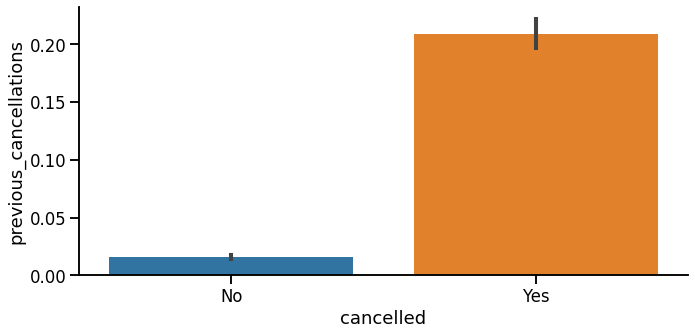

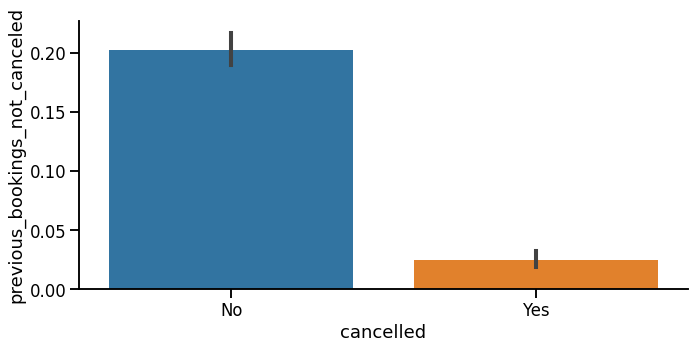

In [6]:
sns.catplot(data=hotel_data, kind='bar', y='previous_cancellations', x="cancelled", aspect=2, height=5);

sns.catplot(data=hotel_data, kind='bar', y='previous_bookings_not_canceled', x="cancelled", aspect=2, height=5);

previous cancellations clearly have an impact on whether this booking was cancelled. this data can't provide a full explanation for this; i think it might be related to your job perhaps being unpredictable, or maybe just being unlucky and having to cancel. 

following on from that thought, i thought maybe exploring market segment bookings might provide some more insight.

### by market segment

In [7]:
#crosstab to see if there's notable differences between segments - there are
pd.crosstab( hotel_data["previous_cancellations_bool"], hotel_data['market_segment'],normalize="columns") 

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
previous_cancellations_bool,,,,,,,,
No,0.962025,0.911171,0.891029,0.985166,0.831003,0.930674,0.989057,1.0
Yes,0.037975,0.088829,0.108971,0.014834,0.168997,0.069326,0.010943,0.0


this crosstab is showing the % of those from each market segment who have or havent cancelled before - e.g. 3.8% of aviation bookings cancelled have cancelled before.

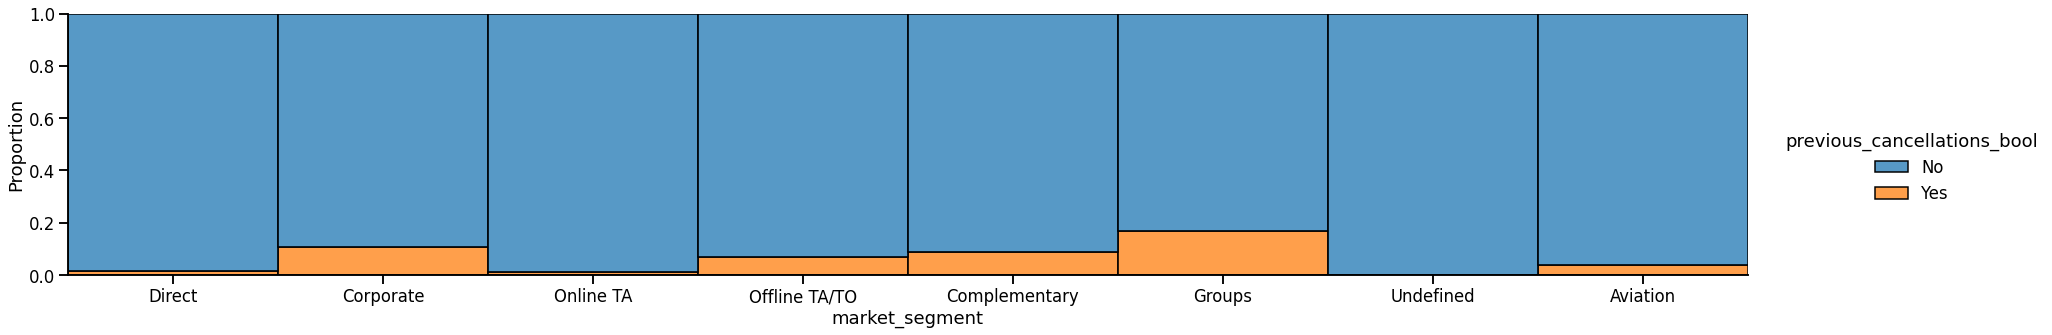

In [8]:
sns.displot(data=hotel_data, x='market_segment', hue='previous_cancellations_bool', stat='proportion', multiple='fill',aspect=5);

offline TA/TOs have higher cancellation rates perhaps because operational errors on behalf of a travel agent force cancellations. same could maybe be said for groups; if you've got more people, you're maybe more likely to have administrative errors that force some sort of a cancellation. the more people youve got, the harder it is to travel together. that might also motivate some of those cancellations? group travelling arrangements might be made and then people pay back for the slots. if the slots don't fill, you'll cancel. that's less likely with any other market segment.

the higher % for complementary is likely because the stay is just that; you didn't seek out the booking, it came to you, and you feel less pressure of monetary loss when you cancel because it's free. people who get complementary stays tend to get a lot of them too, so the effect stacks

the higher corporate cancellation rate  (especially considering they only make up 4.4% of bookings) is perhaps because businesses and their needs are more volatile than holidays for leisure, because you're reliant on lots of other factors to go as planned (including people); if someone important can't make it to the meeting the whole trip gets cancelled. 


## lead time

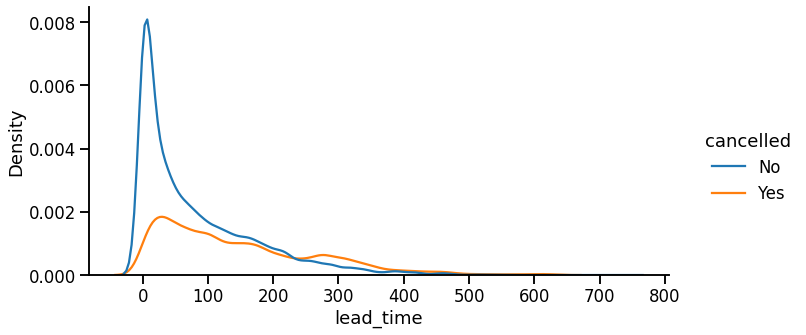

In [9]:
sns.displot(data=hotel_data, kind='kde', x='lead_time', hue='cancelled', aspect=2); 

lead time - how long in advance the booking was made - has a clear impact on cancellation rate. the longer ago the booking was made, the more likely it is to be cancelled, which makes sense; if you're booking for something ~250 days (about 8 months, where the orange line first overtakes the blue) in advance, you don't know what might happen between now and then that might mean you cant go. if you're only booking 2 months in advance, you're more likely to have an accurate picture of the future and what might impact the booking. we can also conclude this from looking at where the spikes are; cancellation spike is slightly after non cancellations.

## special requests

In [10]:
pd.crosstab(hotel_data['cancelled'], hotel_data['total_of_special_requests'], normalize='columns')

total_of_special_requests,0,1,2,3,4,5
cancelled,,,,,,
No,0.522796,0.779751,0.779011,0.821386,0.894118,0.95
Yes,0.477204,0.220249,0.220989,0.178614,0.105882,0.05


<AxesSubplot:xlabel='total_of_special_requests', ylabel='Proportion'>

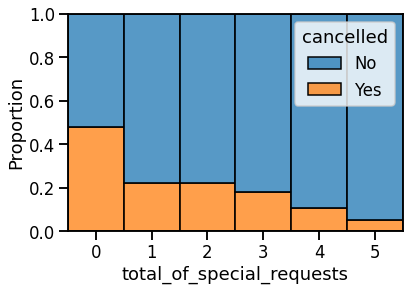

In [11]:
sns.histplot(data=hotel_data,x="total_of_special_requests", hue="cancelled",multiple="fill", stat="proportion",discrete=True)

there's clearly a relationship between number of special requests and cancellation rate; putting the effort in to request special changes means you're wasting your time if you then cancel. but note that the number of available data points for 4 and 5 special requests is much lower than for 0

i used a histogram rather than sns.displot because when you do use sns.displot the bars are really skinny and the comparison is less intuitive.

## days in wait list

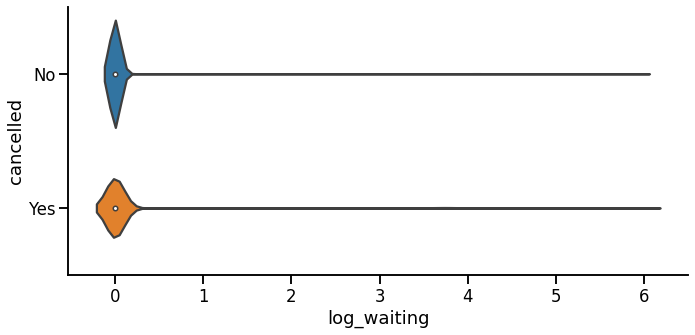

In [12]:
sns.catplot(data=hotel_data, kind='violin', x='log_waiting', y="cancelled", aspect=2, height=5);

there's not really any good way to show how time in the waiting list affects because the plots get skewed by extreme values. i tried to use a log scale to counter this (hence log_waiting rather than days_in_waiting_list) because it helps you identify that most who don't cancel aren't on the waitlist for as long as those who do. 

the increased cancellation rate for longer wait times might be because once they're off the waiting list and receive a reservation, they've had more time to make alternative plans.

## overall market segment 

In [13]:
pd.crosstab( hotel_data["cancelled"], hotel_data['market_segment'],normalize="columns") 

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
cancelled,,,,,,,,
No,0.780591,0.869448,0.812653,0.846581,0.38938,0.65684,0.632789,0.0
Yes,0.219409,0.130552,0.187347,0.153419,0.61062,0.34316,0.367211,1.0


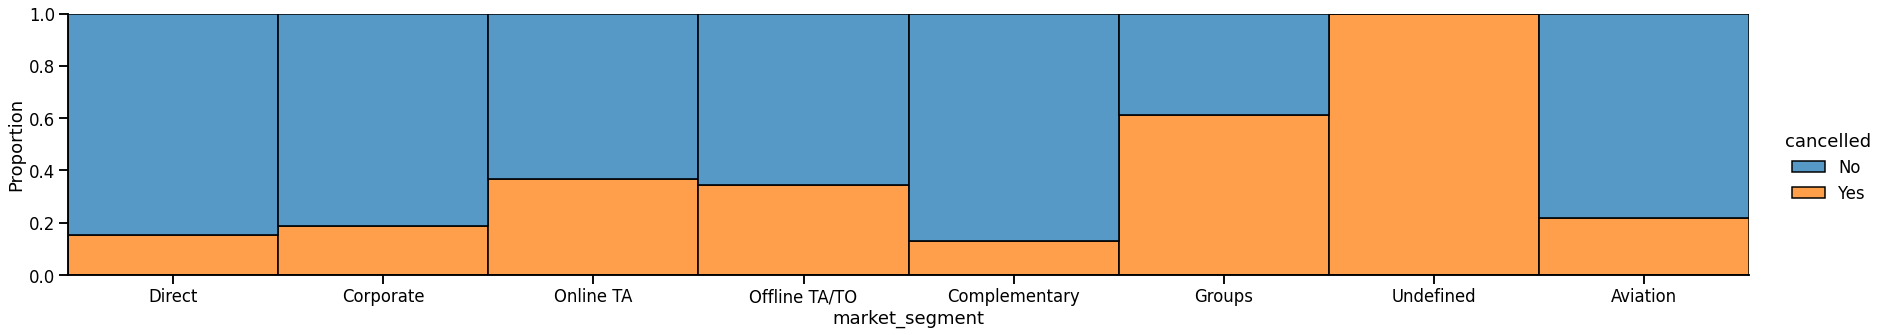

In [14]:
sns.displot(data=hotel_data, x='market_segment', hue='cancelled', stat='proportion', multiple='fill',aspect=5);

i found it quite interesting that repeat cancellers are much less likely to cancel from online TAs than the wider dataset, but im not really sure as to why.

## repeat guests

In [15]:
#repeat guests seem less likely to cancel
pd.crosstab( hotel_data["cancelled"], hotel_data['is_repeated_guest'],normalize="columns") 

is_repeated_guest,0,1
cancelled,,
No,0.622149,0.855118
Yes,0.377851,0.144882


repeat guests are clearly less likely to cancel, which makes sense because if you're booking again you clearly liked it enough the first time, so cancelling because you've decided it's not your thing is much less likely (and perhaps accounting for most of that gap)

## stay length 

In [16]:
#using bins to see if there's anything of note between cancellation rate and stay length that the means calculated at first failed to show
bins = [0,1,5,7,14,21]
labels = ['overnight',"a few days","a week","a week to two weeks","3 weeks plus"]

# create a new feature based on the bins and labels
hotel_data['stays'] = pd.cut(hotel_data['total_stay_length'], bins = bins, labels = labels) #groups data 

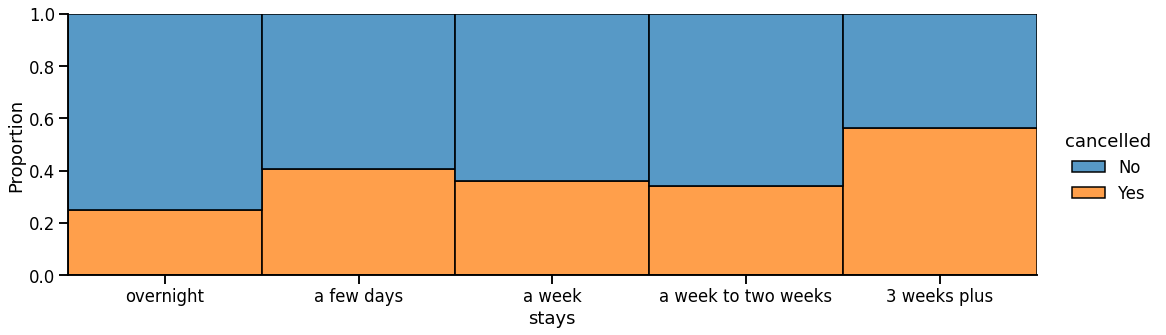

In [17]:
sns.displot(data=hotel_data, x='stays', hue='cancelled', stat='proportion', multiple='fill',aspect=3);

long trips are more likely to be cancelled, but this is a less concrete observation than others simply because there's much less data for those trips (277, just 0.23%). we'd want a bigger data set to confirm, but it might be because 21 days is a long time to be away from home; you're more likely to have something happen which means you need to cut it short. 

## looking at slices

In [18]:
#crosstab helps to identify any differences in cancellation rate within qualitative features
pd.crosstab( hotel_data["cancelled"], hotel_data['hotel'],normalize="columns") 

hotel,City Hotel,Resort Hotel
cancelled,,
No,0.58273,0.722366
Yes,0.41727,0.277634


there seems to be a significant difference between cancellation at the city and resort hotels, so i thought it best to do further analysis on both.

### city data

In [19]:
city_data = hotel_data[hotel_data['hotel'] == "City Hotel"].copy() 

pd.crosstab(city_data['cancelled'], city_data['market_segment'], normalize="columns") 

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
cancelled,,,,,,,,
No,0.780591,0.881919,0.785332,0.826686,0.311413,0.571684,0.626019,0.0
Yes,0.219409,0.118081,0.214668,0.173314,0.688587,0.428316,0.373981,1.0


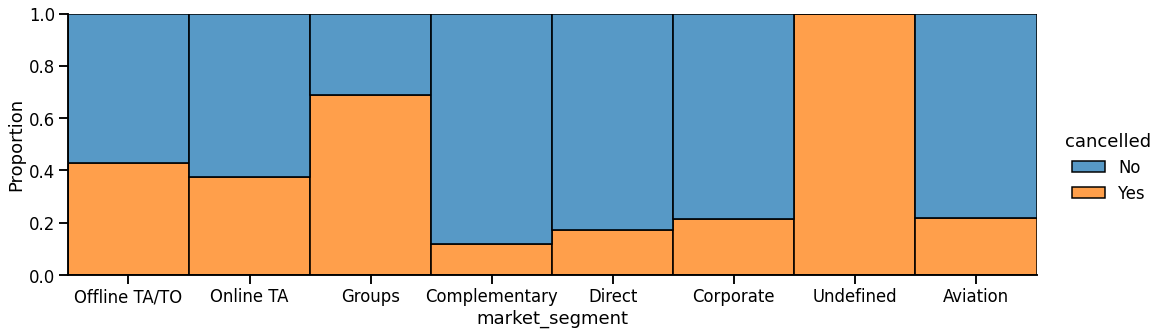

In [20]:
sns.displot(data=city_data, x='market_segment', hue='cancelled', stat='proportion', multiple='fill',aspect=3);

groups and offline TA bookings even more likely to be cancelled at the city hotel compared to wider dataset

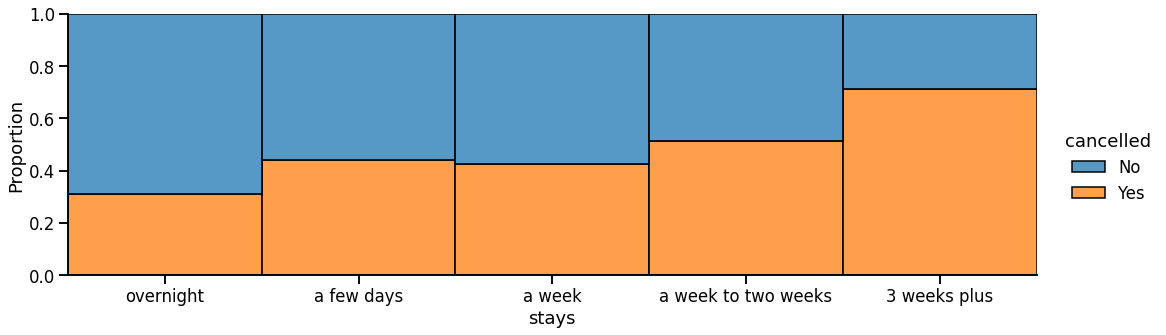

In [21]:
sns.displot(data=city_data, x='stays', hue='cancelled', stat='proportion', multiple='fill',aspect=3);

long stays at the city hotel are also even more likely to be cancelled than the wider dataset

<AxesSubplot:xlabel='total_of_special_requests', ylabel='Proportion'>

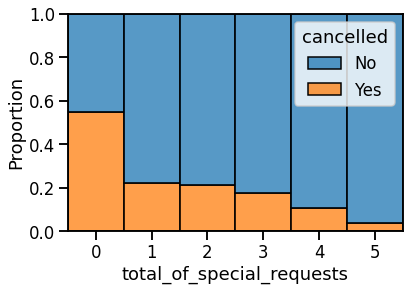

In [22]:
sns.histplot(data=city_data,x="total_of_special_requests", hue="cancelled",multiple="fill", stat="proportion",discrete=True)

similar trend to the wider dataset; more special requests means lower chance of cancelling

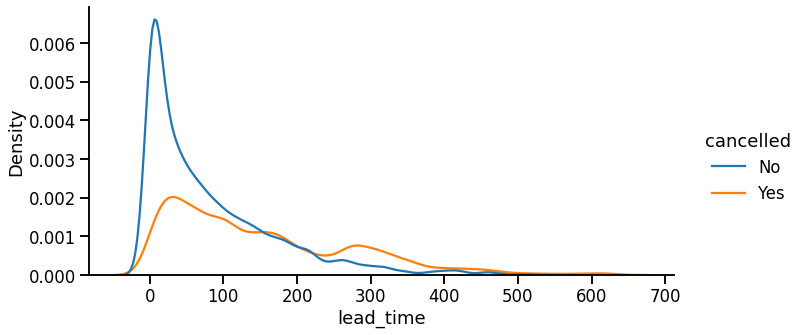

In [23]:
sns.displot(data=city_data, kind='kde', x='lead_time', hue='cancelled', aspect=2); 

the same spike is seen in the city hotel dataset comapred to the wider dataset; most people who cancel have had the booking for a bit longer. 



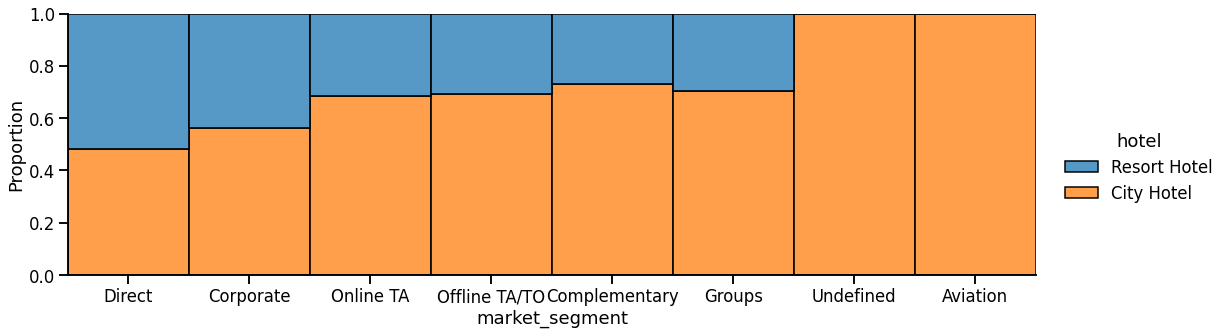

In [24]:
sns.displot(data=hotel_data, x='market_segment', hue='hotel', stat='proportion', multiple='fill',aspect=3);

In [25]:
pd.crosstab(hotel_data['hotel'], hotel_data['market_segment'], normalize="columns") 

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
hotel,,,,,,,,
City Hotel,1.0,0.729475,0.563928,0.483341,0.705416,0.691482,0.686085,1.0
Resort Hotel,0.0,0.270525,0.436072,0.516659,0.294584,0.308518,0.313915,0.0


### hotel data

In [26]:
resort_data = hotel_data[hotel_data['hotel'] == "Resort Hotel"].copy() 

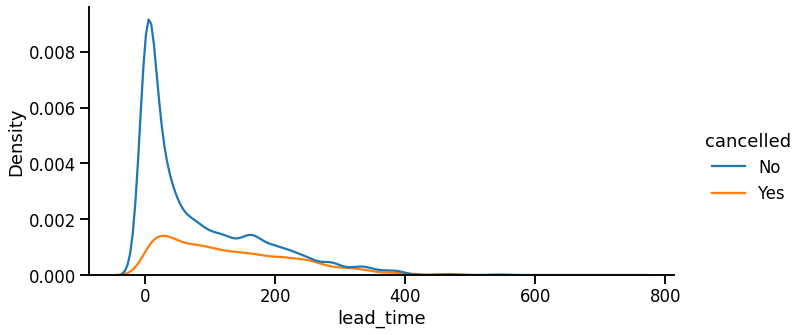

In [27]:
sns.displot(data=resort_data, kind='kde', x='lead_time', hue='cancelled', aspect=2); 

lead time seems fairly similar to whole dataset and city data - lower spike for cancelled bookings because there's fewer cancellations and therefore lower density of them

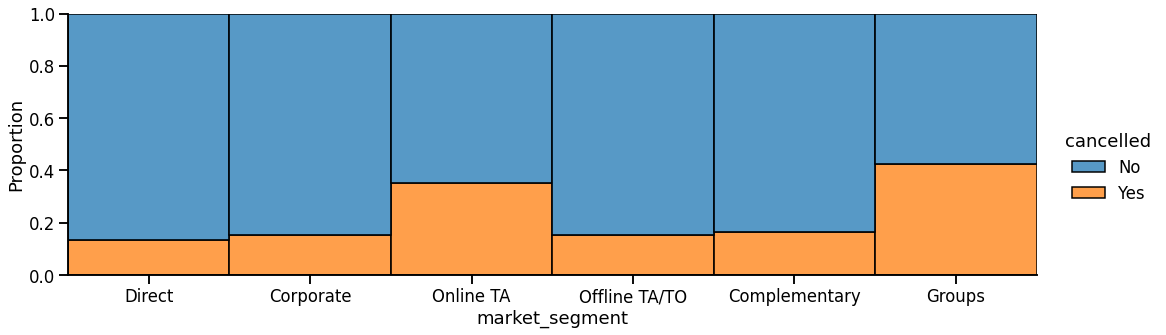

In [28]:
sns.displot(data=resort_data, x='market_segment', hue='cancelled', stat='proportion', multiple='fill',aspect=3);

cancellation rate is much lower across the board at the resort hotel, bar online TA and complementary bookings.

<AxesSubplot:xlabel='total_of_special_requests', ylabel='Proportion'>

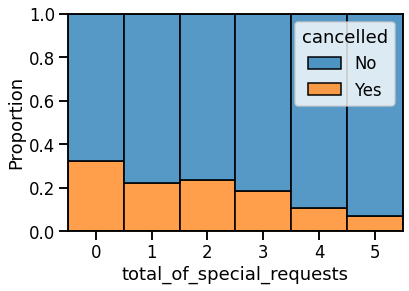

In [29]:
sns.histplot(data=resort_data,x="total_of_special_requests", hue="cancelled",multiple="fill", stat="proportion",discrete=True)

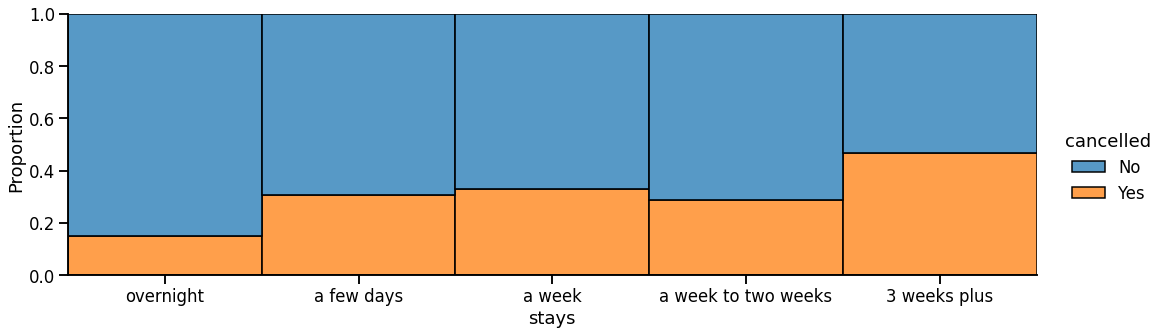

In [30]:
sns.displot(data=resort_data, x='stays', hue='cancelled', stat='proportion', multiple='fill',aspect=3);

overall, the biggest factor differentiating the city and resort hotels that we can identify from the data set is market segment:
- all aviation bookings at the hotel, and theyre more likely to get cancelled because they're reliant on a flight taking off as scheduled
- groups and offline bookings more likely to be cancelled at the hotel compared to the whole dataset

analysis between the two is however severely hindered by the smaller size of the resort dataset, and the small number of factors we have available anyway. 

<a id='model'></a>
# Building models

from exploratory analysis, a few factors emerge as having an impact on cancellation:

- if someone has cancelled before, more likely to cancel again (previous_cancellations)
- also if someone hasn't cancelled before, they're unlikely to now (previous_bookings_not_cancelled)
- longer lead time = higher chance of cancelling (lead_time)
- more special requests = less likely to cancel (total_of_special_requests)
- longer stays are, to an extent, more likely to cancel (total_stay_length)
- repeat guests are less likely to cancel (is_repeat_guest)
- resort hotel bookings are less likely to be cancelled (made numerical using the city_hotel stat) -> i did try to force use of this in some (deleted) models, but it proved to be a hinderance more than anything of use. i'll instead investigate city and hotel bookings through slices

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score
# Function to draw the model
def plot_decision_tree(tree_model, fontsize=12):
 fig, ax = plt.subplots(figsize=(20,8))
 plot_tree(tree_model,
 filled=True,
 impurity=True,
 feature_names=input_features,
 class_names=['No','Yes'],
 proportion=True,
 ax=ax)
 plt.show()

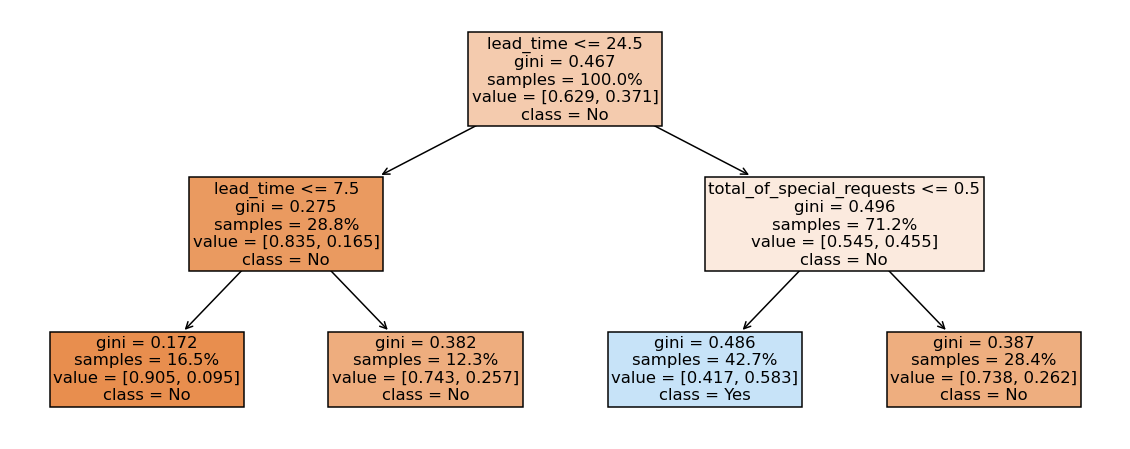

Precision:  57.7 %
Recall:  67.2 %


Predicted,0,1,All
Actual,,,
0,10773,4328,15101
1,2878,5899,8777
All,13651,10227,23878


In [32]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled","lead_time","total_of_special_requests","is_repeated_guest","total_stay_length"]
X = hotel_data[input_features]
y = hotel_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

for my first model, i just inputted the variables i thought were most crucial to determining cancellation rate and made the depth 2 to see what the model would come up with.

this model is pretty decent; fairly good precision and recall.

the hotels are (assumedly) trying to minimise the actual cancellation rate by targeting those who might cancel. therefore, it makes sense to **prioritise recall over precision**; we want to try and catch everyone who might cancel, even if we're not sure they will. more specifically, we want to minimise the number of predicted 0-actual 1. false negatives are worse than false positives here. so the fact this is lower than the predicted 1-actual 0 is encouraging.

of course we can't completely abandon precision, because if the hotel want to, say, offer discounts to everyone who they think might be cancelling, low precision means they'll definitely lose out on a lot of profit from those who had no thought of cancelling in the first place. 

the model for the whole set struggles because there are definite discrepensies between the city and resort hotels, between market segments, that it can't really account for because they're qualitative measures. the model above is as good as we're likely to get




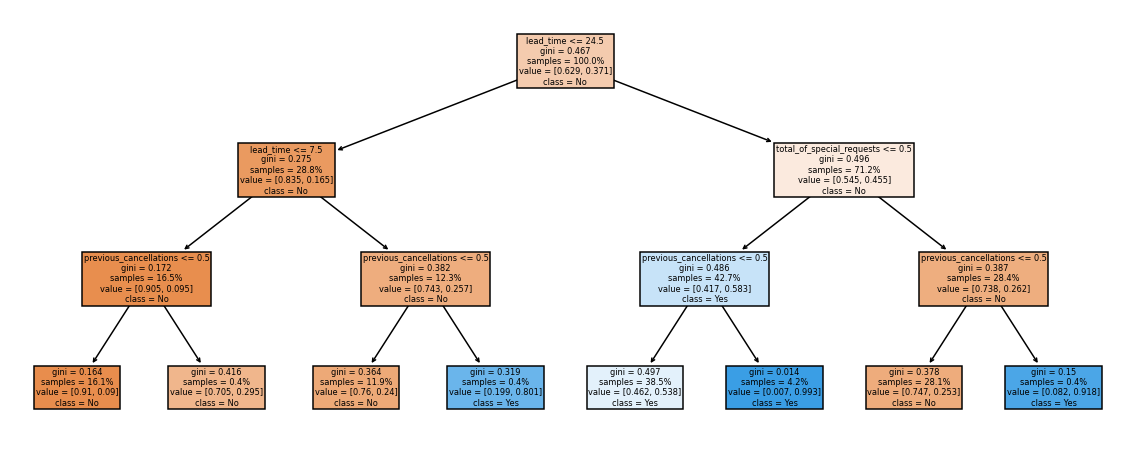

Precision:  58.1 %
Recall:  69.0 %


Predicted,0,1,All
Actual,,,
0,10740,4361,15101
1,2722,6055,8777
All,13462,10416,23878


In [33]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled","lead_time","total_of_special_requests", "is_repeated_guest"]
X = hotel_data[input_features]
y = hotel_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

extending the above model to a depth of 3 slightly increases precision and recall but barely. i dont think the extra computation is really worth it

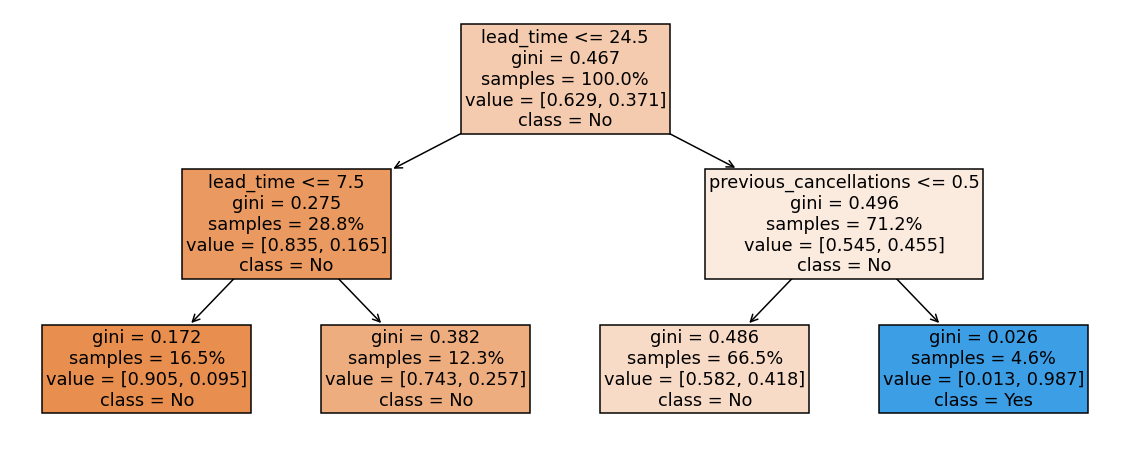

Precision:  98.8 %
Recall:  12.1 %


Predicted,0,1,All
Actual,,,
0,15088,13,15101
1,7717,1060,8777
All,22805,1073,23878


In [34]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled","lead_time", "is_repeated_guest"]
X = hotel_data[input_features]
y = hotel_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

this isn't a model that's actually very useful at all for our purposes - but i did find it worth including as a cool example of the extremes of precision and recall.

## modeling on slices - city and resort hotels

as mentioned above, the city and resort hotels had varying cancellation rates, so producing models for both of them seperately felt suitable. 

### hotel

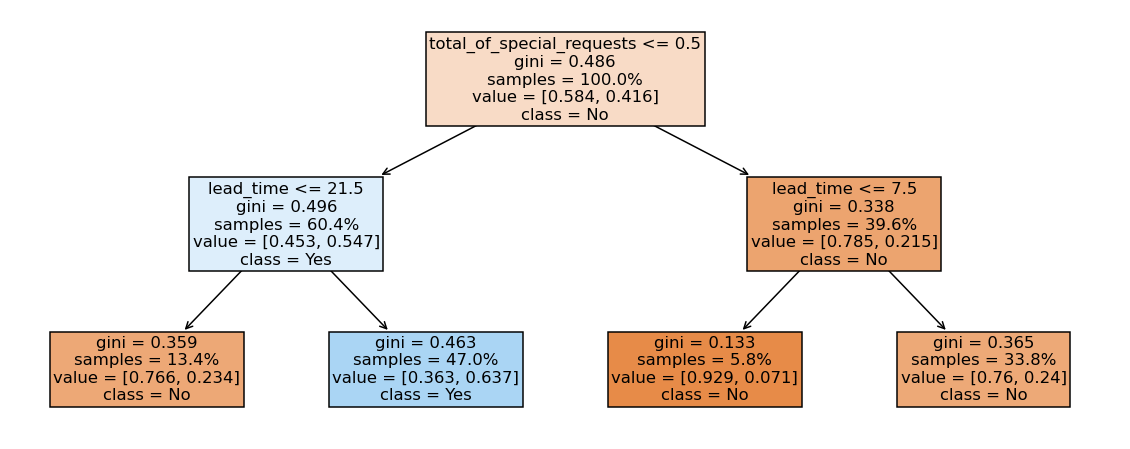

Precision:  64.2 %
Recall:  72.0 %


Predicted,0,1,All
Actual,,,
0,6468,2694,9162
1,1876,4828,6704
All,8344,7522,15866


In [35]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled", "lead_time","is_repeated_guest","total_of_special_requests"]
X = city_data[input_features]
y = city_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

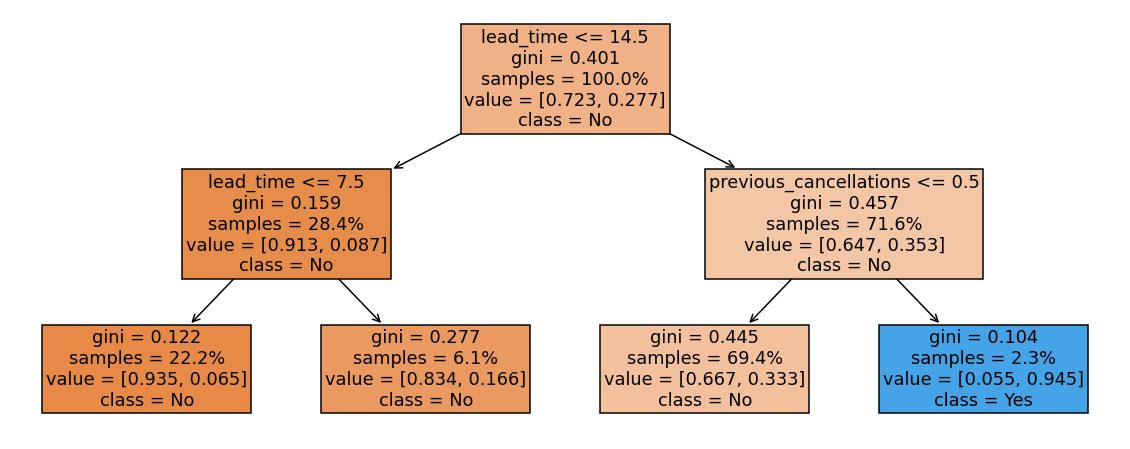

Precision:  96.3 %
Recall:  8.1 %


Predicted,0,1,All
Actual,,,
0,5774,7,5781
1,2051,180,2231
All,7825,187,8012


In [36]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled", "lead_time","is_repeated_guest","total_of_special_requests"]
X = resort_data[input_features]
y = resort_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

### resort

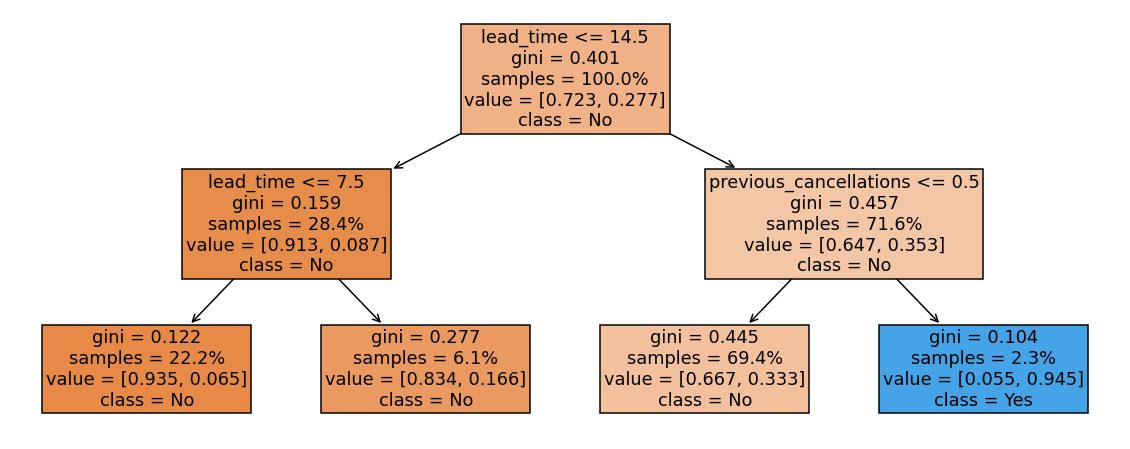

Precision:  96.3 %
Recall:  8.1 %


Predicted,0,1,All
Actual,,,
0,5774,7,5781
1,2051,180,2231
All,7825,187,8012


In [37]:
input_features = ['previous_cancellations',"previous_bookings_not_canceled", "lead_time","is_repeated_guest","total_of_special_requests"]
X = resort_data[input_features]
y = resort_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

this model is genuinely terrible for our goal - prioritising high recall. so i thought that i might've missed something 

In [38]:
resort_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_stay_length,group_size
cancelled,,,,,,,,,,,,,,
No,78.84,1.13,3.01,1.83,0.11,0.02,0.01,0.19,0.34,0.69,0.67,90.79,4.14,1.95
Yes,128.68,1.34,3.44,1.96,0.19,0.01,0.35,0.02,0.15,0.09,0.49,105.79,4.78,2.15


In [39]:
city_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_stay_length,group_size
cancelled,,,,,,,,,,,,,,
No,80.70,0.80,2.12,1.83,0.10,0.01,0.02,0.21,0.26,2.15,0.74,105.75,2.92,1.94
Yes,150.28,0.79,2.27,1.88,0.08,0.00,0.16,0.03,0.08,4.73,0.28,104.69,3.05,1.96


comparing the two, it seems maybe adr is much more of a factor in cancellation for resorts? so i'll add that into the next model and see if it gets used

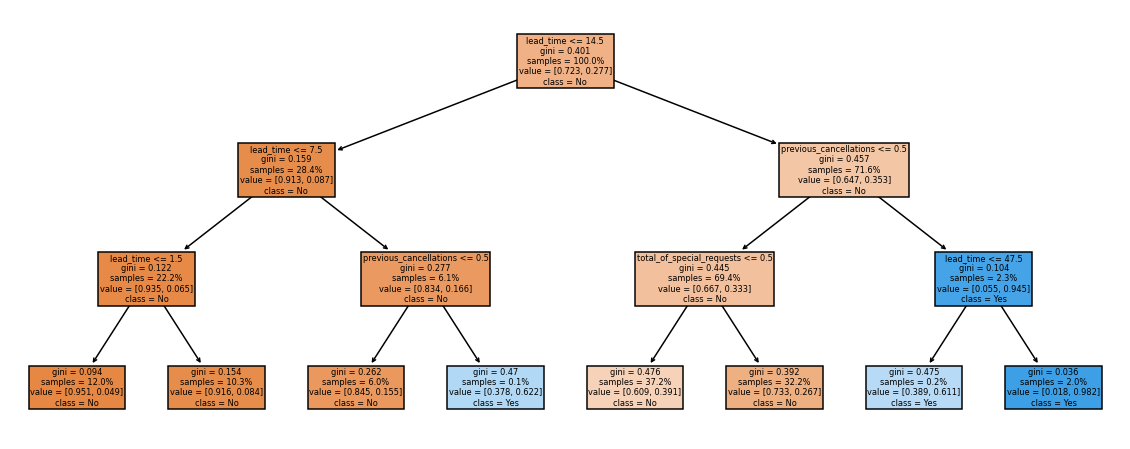

Precision:  95.0 %
Recall:  8.6 %


Predicted,0,1,All
Actual,,,
0,5771,10,5781
1,2039,192,2231
All,7810,202,8012


In [40]:
input_features = ['previous_cancellations',"lead_time","total_of_special_requests","adr"]
X = resort_data[input_features]
y = resort_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

i played around with a whole combination of variables for the resort data but couldnt get recall above about 8.5%. when a model flags cancellation, it's very likely to be right, but it needs overwhelming evidence to do that. so we get lots of false negatives.

that's probably for two reasons - 1, there's double the amount of city hotel bookings (see below), so there's less data for the model to train and refine on. moreover, there's fewer cancellations (proportionally) at the resort hotel, so the set of data the model has to try and identify trends is much much smaller than for the hotel. hence the low recall.

In [41]:
hotel_data['hotel'].value_counts()

City Hotel      79330
Resort Hotel    40060
Name: hotel, dtype: int64

## modeling on slices - market segment 

i wanted to specifically explore cancellations amongst the group segment because my data visualisation suggested that they consistently had a much higher rate of cancellation compared to any other segment of the market. 

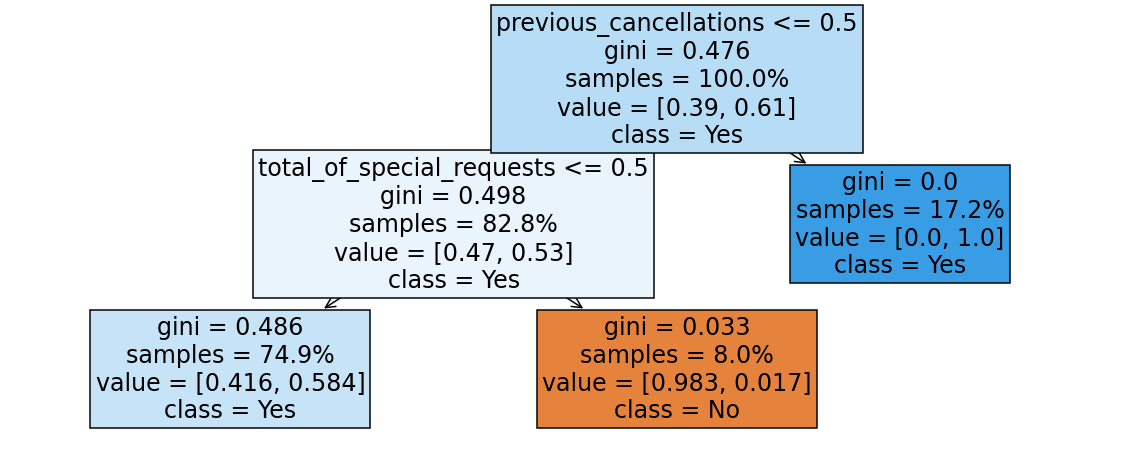

Precision:  66.3 %
Recall:  99.8 %


Predicted,0,1,All
Actual,,,
0,309,1231,1540
1,5,2418,2423
All,314,3649,3963


In [42]:
group_data = hotel_data[hotel_data['market_segment'] == 'Groups'].copy()


input_features = ['previous_cancellations',"previous_bookings_not_canceled", "lead_time","is_repeated_guest","total_of_special_requests"]
X = group_data[input_features]
y = group_data['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)
# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)
# create a list of the predictions and calculate the metrics and confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred, zero_division=0),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

this result actually really surprised me! i didn't expect to get such good recall in any of the models. the model is perhaps helped along by the fact that there are so many cancellations in the group market segment compared to the whole dataset; perhaps that made it easier to identify patterns in the training set because over 50% of group bookings were cancelled. the fact that the data is more specific also definitely helps to push the recall up.

# Conclusions

## evaluating the data

there are some peculiar irregularities in the dataset that put into question how reliable and useful it is for prediction:
- there are 5557 entries where the customer isn't a repeat customer but has recorded previous cancellations?
- there's 715 entries with a stay length of 0 nights (see below.) - some hotels do allow this, but it's very uncommon, especially for a resort hotel. so whilst this might be an issue in the data, it may also just be a weird quirk of portuguese hotels. they're a minute bit of the data (about 0.6%) so won't really impact summary statistics, but an interesting note that the modle might overanalyse

i'm sure that there's more, but those are two that i found whilst conducting exploratory analysis.

moreover:
- the data is from just 2 hotels in one country. whether the apply to other hotels in even that area is up for debate, because these could be two 3 star hotels. the same patterns might not hold for 5 star counterparts. indeed, we don't know if there's a difference in rating between the two hotels we've been given here that could be influencing the models in a way we don't know
- again one country - is this applicable outside of portugal?





In [43]:
len_data = hotel_data[(hotel_data['total_stay_length'] == 0)].copy() 

len_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,total_of_special_requests,adr,is_canceled,cancelled,repeat_guest,previous_cancellations_bool,log_waiting,total_stay_length,group_size,stays
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,...,0,0.0,0,No,No,No,0.0,0,2.0,NaN
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,...,0,0.0,0,No,No,No,0.0,0,2.0,NaN
167,Resort Hotel,BB,Online TA,111,0,0,2,0.0,0,0,...,2,0.0,0,No,No,No,0.0,0,2.0,NaN
168,Resort Hotel,BB,Direct,0,0,0,1,0.0,0,0,...,0,0.0,0,No,No,No,0.0,0,1.0,NaN
196,Resort Hotel,BB,Direct,8,0,0,2,0.0,0,0,...,1,0.0,0,No,No,No,0.0,0,2.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115483,City Hotel,SC,Direct,15,0,0,1,0.0,0,0,...,0,0.0,0,No,No,No,0.0,0,1.0,NaN
117701,City Hotel,BB,Offline TA/TO,0,0,0,2,0.0,0,1,...,0,0.0,0,No,Yes,No,0.0,0,2.0,NaN
118029,City Hotel,BB,Direct,0,0,0,2,0.0,0,1,...,0,0.0,0,No,Yes,No,0.0,0,2.0,NaN
118631,City Hotel,BB,Offline TA/TO,78,0,0,1,0.0,0,0,...,0,0.0,0,No,No,No,0.0,0,1.0,NaN


## conclusions

overall, lead time (higher lead time = more likely to cancel), previous cancellations (those who have cancelled before likely to do so again), and special requests (more special requests = less likely to cancel), all appear to be the most significant factors having a bearing on cancellation rate across both the whole dataset and slices. 

market segment also seemed to have a bearing on cancellation rates, though this wasn't something that could be represented in models. 

the group slice's model was the most 'successful', where we've defined 'success' as a high recall with less regard for precision because it seems important for the hotel to target all those who might cancel to try and get them to not do so (further justification was given above.) this was also likely a result of the high proportion of cancellations giving the model a lot to train on. the city slice's model was also fairly successful for the same reason. 